## LangGraph基础概念

### 一、基本概念

LangGraph中包含的核心组件有：
- **状态（State）**：整个工作流中流转的数据
- **节点（Node）**：工作流中的关键工作代码，主要任务是加工处理State中的数据，用函数来定义
- **边（Edge）**：也可以理解为线，就是把各个节点连接起来的路径，是控制工作流走向的关键

由Edge和Node组成了一个按照特定顺序执行的工作流，也就是**图（Graph）**。

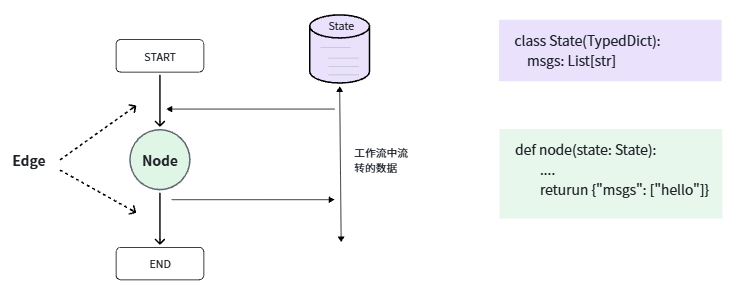

### 二、节点（Node）

节点（Node）用与加工处理 State 数据，多数情况是一个 Python 函数

格式如下：
```python
def my_node(state: State) -> dict:
    # 从state读取数据
    # 执行计算逻辑（可以调用LLM、执行工具、读数据库、文件操作等）
    # 返回state的更新部分（dict）
    return {"age": new_value}
```

需要注意的是，LangGraph有两个默认的Node是无需定义的，可以直接使用：
- START：开始节点，也是入口
- END：结束节点，也是出口

例如，我们要做一个简单的Graph：

- start(用户输入name) --> 节点1（生成问候语）--> 节点2（把问候语转大写）--> end
- START --> greet --> uppercase --> END

In [7]:
from typing import TypedDict
from langgraph.constants import START, END
from langgraph.graph import StateGraph

# ===================1. State: 定义共享数据结构=================
class SimpleState(TypedDict):
    name: str       # 记录用户name
    greeting: str   # 记录生成的问候语

# ===================2. Node: 定义处理逻辑===================
# node 1: 生成问候语的节点
def greet_node(state: SimpleState):
    print(f"greet_node is receiving name: {state['name']}")
    return {"greeting": f"Hello, {state['name']}!"}

# node 2: 转大写
def uppercase_node(state: SimpleState):
    print(f"uppercase_node is receiving greeting: {state['greeting']}")
    return {"greeting": state["greeting"].upper()}

# ===================3. 创建Graph===================
graph_builder = StateGraph(SimpleState)             # 3.1.注册State，初始化图Builder
                                                    # 3.2.注册节点
graph_builder.add_node("greet", greet_node)             # greet节点
graph_builder.add_node("uppercase", uppercase_node)     # uppercase节点
                                                    # 3.3.注册Edge，定义Node执行顺序
graph_builder.add_edge(START, "greet")                  # START -> greet
graph_builder.add_edge("greet", "uppercase")            # greet -> uppercase
graph_builder.add_edge("uppercase", END)                # uppercase -> END

graph = graph_builder.compile()                     # 3.4.编译成可执行图

# ===================4.调用graph======================
# 调用graph，传入初始的state，返回的是处理后的 state
result = graph.invoke({"name": "World"})
print(result)

greet_node is receiving name: World
uppercase_node is receiving greeting: Hello, World!
{'name': 'World', 'greeting': 'HELLO, WORLD!'}


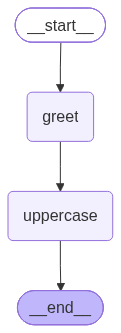

In [8]:
from IPython.display import Image, display
display(Image(graph.get_graph(xray=True).draw_mermaid_png()))

总结，创建Graph的一般流程是这样的：
- 定义State，定义数据结构
- 定义Node，定义数据处理逻辑
- 创建Graph，分为几部分：
  - 注册State，初始化GraphBuilder
  - 注册Node
  - 注册Edge，定义Node执行顺序
  - 编译，得到Graph
- 执行Graph

### 二、State（状态）

State 是图的共享内存数据，贯穿整个执行过程
- 整个数据仅保留一份，每个节点都可以获取或更新 State 数据
- State 会通过 `Reducer` 函数处理字段的旧值和新值
    - State 中每个字段都有自己的 `Reducer`
    - 如果字段没有指定 `Reducer`，那默认就是覆盖，也就是说，多个 Node 同时更新同一个字段时，后执行的会覆盖先执行的更新结果

自定义 Reducer

In [15]:
from typing import Annotated, TypedDict
from langgraph.constants import START, END
from langgraph.graph import StateGraph

# 定义 Reducer 函数
def add_reducer(old, new):
    return old + new

# =================1. 定义State数据结构和Reducer=================
class CustomReducerState(TypedDict):
    count: int                               # 这个字段没有定义Reducer，也就是默认会覆盖旧值
    nodes: Annotated[list[str], add_reducer] # 这里使用add作为Reducer，也就是会拼接结果

# =================2. Node: 定义处理逻辑=================
def node_1(state: CustomReducerState):
    print(f'node_1 is receiving count: {state['count']}')
    return {'count': state['count'] + 1, 'nodes': ['node_1']} # 直接修改nodes值，不用自己拼接

def node_2(state: CustomReducerState):
    print(f'node_2 is receiving count: {state['count']}')
    return {'count': state['count'] + 1, 'nodes': ['node_2']} # 直接修改nodes值，不用自己拼接

# ===================3. 创建Graph===================
graph_builder = StateGraph(CustomReducerState)      # 3.1.注册State，初始化图Builder
graph_builder.add_node('node_1', node_1)            # 3.2.注册Node
graph_builder.add_node('node_2', node_2)
                                                    # 3.3.注册Edge，定义Node执行顺序
graph_builder.add_edge(START, 'node_1')                 # START -> greet
graph_builder.add_edge('node_1', 'node_2')              # greet -> uppercase
graph_builder.add_edge('node_2', END)                   # uppercase -> END

graph = graph_builder.compile()                     # 3.4.编译成可执行图

# =================4.调用Graph，传入默认State值=================
result = graph.invoke({'count': 0, 'nodes':[]})
print(result)

node_1 is receiving count: 0
node_2 is receiving count: 1
{'count': 2, 'nodes': ['node_1', 'node_2']}


### 三、Edge（边）

边（Edge）可以定义图中节点的执行顺序，连接节点（Node），形成图（Graph）

| 边类型 | 方法 | 说明 |
| :--- | :--- | :--- |
| 普通边 (Normal Edge) | `add_edge(node_a, node_b)` | 固定流向：A执行完一定到B |
| 条件边 (Conditional Edge) | `add_conditional_edges(node_a, router, mapping)` | router的返回值决定下一节点 |

示意图:

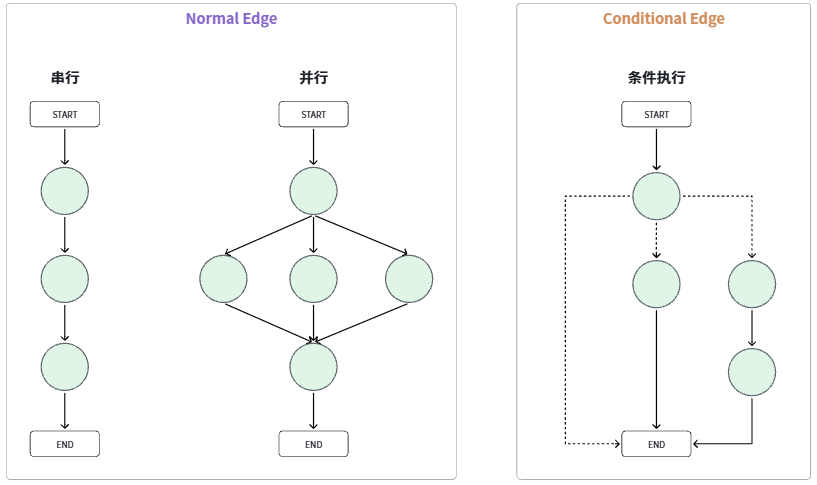
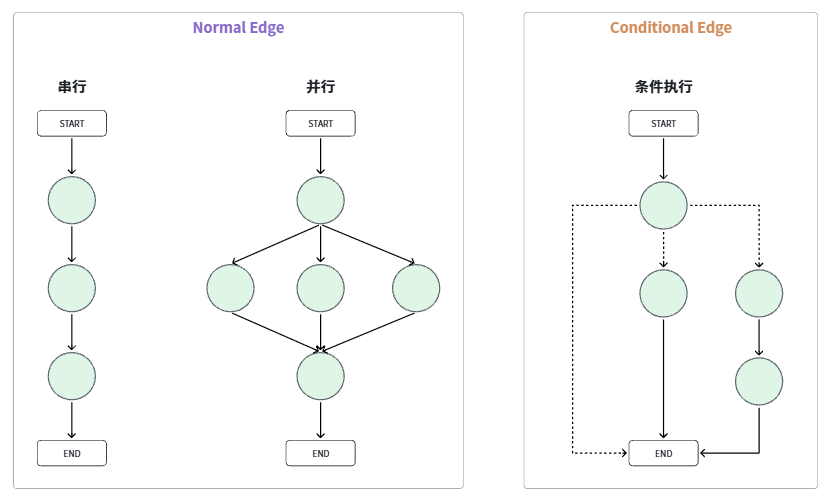

#### 3.1 Normal Edge（普通边、并行）

普通边连接的两个节点流向是固定的，前一个节点执行完一定会执行后一个节点。不同之处在于节点之间是串行还是并行：
- **串行**: 整个工作流只有一条路径，路径中的节点按照顺序依次执行
- **并行**: 整个工作流由多条路径，不同路径可以并行执行，提高效率

上述我们演示的就是串行方式，本节课我们再来看看并行方式，结构如图：
```
      ┌──>  b ───┐
a ────┤          ├────> d
      └──>  c ───┘
```

In [22]:
from time import sleep
from operator import add
from typing import Annotated, TypedDict
from langgraph.constants import START, END
from langgraph.graph import StateGraph
from datetime import datetime

# =================1. 定义State数据结构和Reducer=================
class ParallelState(TypedDict):
    nodes: Annotated[list[str], add]

# =================2. Node: 定义处理逻辑=================
def node_a(state: ParallelState):
    print(f"node_a is running, nodes: {state['nodes']}")
    return {"nodes": ["a"]}

def node_b(state: ParallelState):
    sleep(1)
    print(f"node_b is running, nodes: {state['nodes']}, time: {datetime.now()}")
    return {"nodes": ["b"]}

def node_c(state: ParallelState):
    print(f"node_c is running, nodes: {state['nodes']}, time: {datetime.now()}")
    return {"nodes": ["c"]}

def node_d(state: ParallelState):
    print(f"node_d is running, nodes: {state['nodes']}")
    return {"nodes": ["d"]}

# ===================3. 创建Graph===================
builder = StateGraph(ParallelState)
builder.add_node("a", node_a)
builder.add_node("b", node_b)
builder.add_node("c", node_c)
builder.add_node("d", node_d)
builder.add_edge(START, "a")         # start -> a
builder.add_edge("a", "b")           # a -> b
builder.add_edge("a", "c")           # a -> c
builder.add_edge("b", "d")           # b -> d
builder.add_edge("c", "d")           # c -> d
builder.add_edge("d", END)           # d -> end
parallel_graph = builder.compile()

# =================4.调用Graph，传入默认State值=================
result = parallel_graph.invoke({})
print(result)

node_a is running, nodes: []
node_c is running, nodes: ['a'], time: 2026-11-09 15:04:06.278927
node_b is running, nodes: ['a'], time: 2026-11-09 15:04:07.278852
node_d is running, nodes: ['a', 'b', 'c']
{'nodes': ['a', 'b', 'c', 'd']}


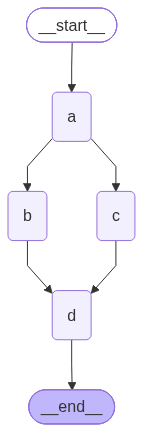

In [23]:
from IPython.display import Image, display
display(Image(parallel_graph.get_graph(xray=True).draw_mermaid_png()))

注意事项：
- 并行节点会拿到相同的 State 数据，分别处理，再汇总 State
- 并行节点如果修改了 State 的同一个字段，`必须自定义 Reducer`

#### 3.2 Conditional Edge（条件边）

条件边的添加方式如下：
```
add_conditional_edges(node_a, router, mapping)
```

接收三个参数：
- `node_a`：是当前节点（这条边开始）
- `router`：路由函数，逻辑自定义，它的返回值默认就是下个节点的名字。
- `mapping`：如果router返回值与下个节点名不一样，可以用mapping定义返回值与下个节点名字的映射关系

例如，我们实现一个成绩判定的Graph，用户输入一个分数，我们根据分数判断走哪个节点：
- 大于60，走成功节点
- 小于60，走失败节点

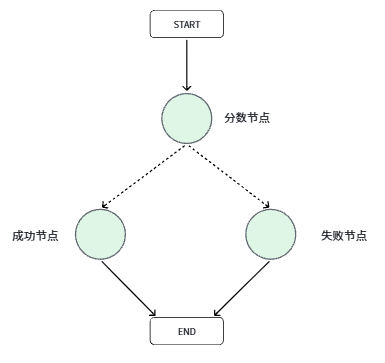

In [25]:
from typing import TypedDict, Literal
from langgraph.constants import START, END
from langgraph.graph import StateGraph
# =================1. 定义State数据结构================
class RouteState(TypedDict):
    score: int
    result: str

# =================2. Node: 定义处理逻辑=================
def scorer(state: RouteState):
    score = int(input("请输入分数:"))
    print(score)
    return {"score": score}  # 模拟评分

def pass_node(state: RouteState):
    return {"result": "通过！"}

def fail_node(state: RouteState):
    return {"result": "不通过"}

# =================3. 定义路由节点，决定下个Node=================
def router(state: RouteState) -> Literal["pass", "fail"]: # 告诉LangGraph返回的是这两个节点
    """根据score决定下一节点"""
    if state["score"] >= 60:
        return "pass"
    return "fail"

# ===================4. 创建Graph===================

builder = StateGraph(RouteState)                # 1.创建Graph
                                                # 2.添加节点
builder.add_node("scorer", scorer)                  # 打分节点
builder.add_node("pass", pass_node)                 # 失败节点
builder.add_node("fail", fail_node)                 # 成功节点
                                                # 3.添加Edge
builder.add_edge(START, "scorer")                   # start -> scorer
builder.add_conditional_edges("scorer", router)     # scorer -> router （条件边）
builder.add_edge("pass", END)                       # pass -> end
builder.add_edge("fail", END)                       # fail -> end
condition_graph=builder.compile()

# =================5.调用Graph，传入默认State值=================
result = condition_graph.invoke({"score": 0, "result": ""})
print(result)

20
{'score': 20, 'result': '不通过'}


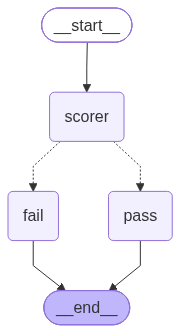

In [27]:
from IPython.display import Image, display
display(Image(condition_graph.get_graph(xray=True).draw_mermaid_png()))

#### 3.3 Command 实现条件分支

```
def node_a(state: State) -> Command[Literal['node_b', 'node_c']]:
    # ...
    return Command(
        update={"k":"v"}, # 用来指定要更新的State字段
        goto="node_b"     # 用来指定下个节点
    )
```

In [29]:
from typing import TypedDict, Literal
from langgraph.constants import START, END
from langgraph.graph import StateGraph
from langgraph.types import Command

# =================1. 定义State数据结构================
class RouteState(TypedDict):
    score: int
    result: str

# =================2. Node: 定义处理逻辑=================

# scorer节点自己负责路由，需要注意其返回值必须是Literal
def scorer(state: RouteState) -> Command[Literal["pass", "fail"]]:
    score = int(input("请输入分数:"))
    goto = "fail"
    if score >= 60:
        goto = "pass"
    return Command( # 通过Command的update更新State，goto指定下一个节点
        update={"score": score},
        goto=goto
    )

def pass_node(state: RouteState):
    return {"result": "通过！"}

def fail_node(state: RouteState):
    return {"result": "不通过"}

# ===================3. 创建Graph===================

builder = StateGraph(RouteState)                # 1.创建Graph
                                                # 2.添加节点
builder.add_node("scorer", scorer)                  # 打分节点
builder.add_node("pass", pass_node)                 # 失败节点
builder.add_node("fail", fail_node)                 # 成功节点
                                                # 3.添加Edge
builder.add_edge(START, "scorer")               # start -> scorer
builder.add_edge("pass", END)                   # pass -> end
builder.add_edge("fail", END)                   # fail -> end
condition_graph=builder.compile()

# =================4.调用Graph，传入默认State值=================
result = condition_graph.invoke({"score": 0, "result": ""})
print(result)

{'score': 1111, 'result': '通过！'}


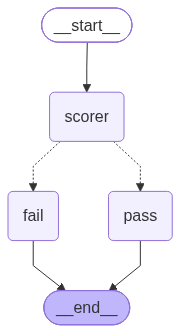

In [30]:
from IPython.display import Image, display
display(Image(condition_graph.get_graph(xray=True).draw_mermaid_png()))